# Customer Analytics & Churn Prediction
## End-to-End Data Pipeline: EDA → Feature Engineering → ML

**Objective:** Analyze customer behavior, segment customers using RFM analysis, and build machine learning models to predict churn.

**Tools:** Python · pandas · scikit-learn · matplotlib · seaborn · openpyxl  
**Dataset:** 500 customers with purchase and interaction history  
**Reference Date:** June 30, 2025

In [1]:
# Step 1: Import Libraries & Path Setup
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve)
import warnings
warnings.filterwarnings('ignore')

# Smart path resolution (handles running from project root OR notebooks folder)
if os.path.exists('data'):
    DATA_DIR = 'data'
    OUTPUT_DIR = 'outputs'
elif os.path.exists('../data'):
    DATA_DIR = '../data'
    OUTPUT_DIR = '../outputs'
else:
    DATA_DIR = 'data'
    OUTPUT_DIR = 'outputs'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# Plot configuration
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✓ All libraries imported successfully!')
print(f'✓ Data directory:   {os.path.abspath(DATA_DIR)}')
print(f'✓ Output directory: {os.path.abspath(OUTPUT_DIR)}')

✓ All libraries imported successfully!
✓ Data directory:   C:\Users\ashis\Desktop\Customer_Analytics_Project\data
✓ Output directory: C:\Users\ashis\Desktop\Customer_Analytics_Project\outputs


## 1. Data Loading

We work with three relational datasets:
- **Customers** — demographics, signup date, country (500 records)
- **Orders** — purchase transactions with amounts, categories, and payment methods
- **Interactions** — customer engagement across channels (website, email, support, phone, chat)

In [2]:
# Step 2: Load Data
if 'DATA_DIR' not in globals():
    import os
    DATA_DIR = 'data' if os.path.exists('data') else ('../data' if os.path.exists('../data') else 'data')

customers_df = pd.read_csv(os.path.join(DATA_DIR, 'customers.csv'))
orders_df = pd.read_csv(os.path.join(DATA_DIR, 'orders.csv'))
interactions_df = pd.read_csv(os.path.join(DATA_DIR, 'customer_interactions.csv'))

print(f'✓ Customers:    {customers_df.shape[0]:>5} rows × {customers_df.shape[1]} columns')
print(f'✓ Orders:       {orders_df.shape[0]:>5} rows × {orders_df.shape[1]} columns')
print(f'✓ Interactions: {interactions_df.shape[0]:>5} rows × {interactions_df.shape[1]} columns')
print(f'\nTotal records: {len(customers_df) + len(orders_df) + len(interactions_df):,}')

✓ Customers:      500 rows × 7 columns
✓ Orders:        3742 rows × 7 columns
✓ Interactions:  2946 rows × 6 columns

Total records: 7,188


In [3]:
# Step 3: Explore the data
print("=== CUSTOMERS (first 5 rows) ===")
display(customers_df.head())

print("\n=== ORDERS (first 5 rows) ===")
display(orders_df.head())

print("\n=== INTERACTIONS (first 5 rows) ===")
display(interactions_df.head())

=== CUSTOMERS (first 5 rows) ===


,customer_id,customer_name,email,signup_date,country,age,gender
0,1001,Meera Patel,customer1001@email.com,2023-06-16,Germany,33,M
1,1002,Kiran Zhang,customer1002@email.com,2024-11-09,Mexico,23,F
2,1003,Amit Reddy,customer1003@email.com,2025-02-27,Australia,32,M
3,1004,Shreya Wang,customer1004@email.com,2023-09-04,Mexico,44,M
4,1005,Olivia Sharma,customer1005@email.com,2023-12-28,Canada,62,F



=== ORDERS (first 5 rows) ===


,order_id,customer_id,order_date,order_amount,product_category,payment_method,order_status
0,10001,1001,2025-05-12,237.22,Fashion,PayPal,Completed
1,10002,1001,2024-10-29,551.33,Beauty,Google Pay,Completed
2,10003,1001,2024-07-21,607.65,Beauty,PayPal,Pending
3,10004,1001,2025-03-09,213.90,Sports,Google Pay,Completed
4,10005,1001,2025-05-04,177.25,Fashion,Debit Card,Completed



=== INTERACTIONS (first 5 rows) ===


,interaction_id,customer_id,interaction_date,interaction_type,duration_minutes,channel
0,5001,1001,2025-05-16,support_ticket,21,Website
1,5002,1001,2025-06-06,website_visit,70,Chat
2,5003,1001,2024-08-08,chat,38,Support
3,5004,1001,2023-12-07,support_ticket,50,Support
4,5005,1001,2024-11-23,chat,39,Chat


In [4]:
# Step 4: Data Quality Check
print("=== DATA QUALITY REPORT ===\n")
for name, df in [('Customers', customers_df), ('Orders', orders_df), ('Interactions', interactions_df)]:
    print(f"--- {name} ---")
    print(f"  Shape: {df.shape}")
    print(f"  Missing values: {df.isnull().sum().sum()}")
    print(f"  Duplicates: {df.duplicated().sum()}")
    print()

print("Order Status Distribution:")
print(orders_df['order_status'].value_counts().to_string())
print("\nProduct Categories:")
print(orders_df['product_category'].value_counts().to_string())

=== DATA QUALITY REPORT ===

--- Customers ---
  Shape: (500, 7)
  Missing values: 0
  Duplicates: 0

--- Orders ---
  Shape: (3742, 7)
  Missing values: 0
  Duplicates: 0

--- Interactions ---
  Shape: (2946, 6)
  Missing values: 0
  Duplicates: 0

Order Status Distribution:
order_status
Completed    3001
Pending       373
Cancelled     190
Returned      178

Product Categories:
product_category
Fashion          398
Home & Garden    394
Furniture        387
Beauty           383
Sports           382
Toys             380
Food             373
Electronics      370
Books            339
Technology       336


## 2. Data Cleaning & Preprocessing

Convert date columns from strings to datetime objects and set a consistent reference date for all time-based calculations. The reference date **must match** the data generation script to avoid negative values.

In [5]:
# Step 5: Convert Dates
customers_df['signup_date'] = pd.to_datetime(customers_df['signup_date'])
orders_df['order_date'] = pd.to_datetime(orders_df['order_date'])
interactions_df['interaction_date'] = pd.to_datetime(interactions_df['interaction_date'])

# Reference date — MUST match the data generation script
REFERENCE_DATE = pd.Timestamp('2025-06-30')

print(f'✓ Date columns converted')
print(f'✓ Reference date: {REFERENCE_DATE.date()}')
print(f'\nSignup range:  {customers_df["signup_date"].min().date()} → {customers_df["signup_date"].max().date()}')
print(f'Order range:   {orders_df["order_date"].min().date()} → {orders_df["order_date"].max().date()}')

✓ Date columns converted
✓ Reference date: 2025-06-30

Signup range:  2023-01-02 → 2025-03-29
Order range:   2023-01-08 → 2025-06-30


## 3. Feature Engineering

Build customer-level features by aggregating orders and interactions. This is the core transformation step — converting raw transaction data into meaningful analytical features.

**Purchase Metrics:** order count, total spending, average order value, first/last purchase dates  
**Interaction Metrics:** interaction count, last interaction, total engagement time

In [6]:
# Step 6: Calculate Purchase Metrics
purchase_metrics = orders_df.groupby('customer_id').agg(
    purchase_count=('order_id', 'count'),
    total_spent=('order_amount', 'sum'),
    avg_order_value=('order_amount', 'mean'),
    first_purchase_date=('order_date', 'min'),
    last_purchase_date=('order_date', 'max')
).reset_index()

print(f'✓ Purchase metrics for {len(purchase_metrics)} customers')
print(f'  Avg purchases/customer: {purchase_metrics["purchase_count"].mean():.1f}')
print(f'  Avg total spent:        ${purchase_metrics["total_spent"].mean():,.2f}')

✓ Purchase metrics for 485 customers
  Avg purchases/customer: 7.7
  Avg total spent:        $4,059.15


In [7]:
# Step 7: Calculate Interaction Metrics
interaction_metrics = interactions_df.groupby('customer_id').agg(
    total_interactions=('interaction_id', 'count'),
    last_interaction_date=('interaction_date', 'max'),
    total_interaction_minutes=('duration_minutes', 'sum')
).reset_index()

print(f'✓ Interaction metrics for {len(interaction_metrics)} customers')

✓ Interaction metrics for 477 customers


In [8]:
# Step 8: Merge into Master DataFrame
master_df = customers_df.copy()
master_df = master_df.merge(purchase_metrics, on='customer_id', how='left')
master_df = master_df.merge(interaction_metrics, on='customer_id', how='left')

# Fill missing values (customers with no orders/interactions)
numeric_fills = {
    'purchase_count': 0, 'total_spent': 0, 'avg_order_value': 0,
    'total_interactions': 0, 'total_interaction_minutes': 0
}
master_df = master_df.fillna(numeric_fills)
master_df['purchase_count'] = master_df['purchase_count'].astype(int)
master_df['total_interactions'] = master_df['total_interactions'].astype(int)

print(f'✓ Master dataframe: {master_df.shape}')
print(f'  Customers with orders:    {(master_df["purchase_count"] > 0).sum()}')
print(f'  Customers without orders: {(master_df["purchase_count"] == 0).sum()}')

✓ Master dataframe: (500, 15)
  Customers with orders:    485
  Customers without orders: 15


## 4. RFM Analysis & Customer Segmentation

**RFM (Recency, Frequency, Monetary)** is a proven marketing analysis technique used by companies like Amazon and Netflix:

| Metric | Definition | Better When |
|--------|-----------|-------------|
| **Recency** | Days since last purchase | Lower |
| **Frequency** | Total number of purchases | Higher |
| **Monetary** | Total spending ($) | Higher |

We also compute **CLV (Customer Lifetime Value)**, **Engagement Score**, and a **Churn Label** (inactive >90 days).

In [9]:
# Step 9: Calculate RFM & Derived Features
master_df['recency'] = (REFERENCE_DATE - master_df['last_purchase_date']).dt.days
# Customers with no purchases → maximum recency (most likely churned)
master_df.loc[master_df['last_purchase_date'].isna(), 'recency'] = 999

master_df['frequency'] = master_df['purchase_count']
master_df['monetary'] = master_df['total_spent']
master_df['customer_age_days'] = (REFERENCE_DATE - master_df['signup_date']).dt.days

# Customer Lifetime Value (annualized spending)
master_df['clv_score'] = (master_df['total_spent'] / (master_df['customer_age_days'] + 1)) * 365

# Engagement Score (interactions per 100 days of tenure)
master_df['engagement_score'] = (
    master_df['total_interactions'] / (master_df['customer_age_days'] + 1) * 100
).clip(lower=0)

# Purchase frequency per month
master_df['purchase_frequency_monthly'] = (
    master_df['purchase_count'] / (master_df['customer_age_days'] / 30 + 1)
)

print('✓ RFM & derived features calculated')
print(f'\n  Recency:   mean={master_df["recency"].mean():.0f} days, median={master_df["recency"].median():.0f}')
print(f'  Frequency: mean={master_df["frequency"].mean():.1f}, max={master_df["frequency"].max()}')
print(f'  Monetary:  mean=${master_df["monetary"].mean():,.2f}, max=${master_df["monetary"].max():,.2f}')

✓ RFM & derived features calculated

  Recency:   mean=90 days, median=33
  Frequency: mean=7.5, max=15
  Monetary:  mean=$3,937.38, max=$9,573.93


In [10]:
# Step 10: RFM Scoring (1-5 scale)
master_df['recency_score'] = pd.qcut(
    master_df['recency'], 5, labels=[5, 4, 3, 2, 1], duplicates='drop'
).astype(float)

master_df['frequency_score'] = pd.qcut(
    master_df['frequency'].rank(method='first'), 5,
    labels=[1, 2, 3, 4, 5], duplicates='drop'
).astype(float)

master_df['monetary_score'] = pd.qcut(
    master_df['monetary'].rank(method='first'), 5,
    labels=[1, 2, 3, 4, 5], duplicates='drop'
).astype(float)

master_df['rfm_total_score'] = (
    master_df['recency_score'] +
    master_df['frequency_score'] +
    master_df['monetary_score']
)

print('✓ RFM scores assigned (1–5 scale)')
print(f'\nRFM Score Distribution:')
print(master_df['rfm_total_score'].describe().round(2))

✓ RFM scores assigned (1–5 scale)

RFM Score Distribution:
count    500.00
mean       9.02
std        3.77
min        3.00
25%        6.00
50%        9.00
75%       12.00
max       15.00
Name: rfm_total_score, dtype: float64


In [11]:
# Step 11: Customer Segmentation & Churn Labels
def segment_customer(score):
    if score >= 13:   return 'VIP'
    elif score >= 10: return 'Loyal'
    elif score >= 7:  return 'At Risk'
    else:             return 'Lost'

master_df['rfm_segment'] = master_df['rfm_total_score'].apply(segment_customer)

# Churn label: inactive for >90 days (realistic threshold)
master_df['churned'] = (master_df['recency'] > 90).astype(int)

# Value segmentation
def segment_by_value(clv):
    if clv > 500:   return 'High Value'
    elif clv > 200: return 'Medium Value'
    elif clv > 0:   return 'Low Value'
    else:           return 'No Purchase'

master_df['value_segment'] = master_df['clv_score'].apply(segment_by_value)

churn_rate = master_df['churned'].mean() * 100
print(f'✓ Segmentation completed')
print(f'\n📊 Churn Rate: {churn_rate:.1f}%')
print(f'\nRFM Segments:')
print(master_df['rfm_segment'].value_counts().to_string())
print(f'\nValue Segments:')
print(master_df['value_segment'].value_counts().to_string())

✓ Segmentation completed

📊 Churn Rate: 22.6%

RFM Segments:
rfm_segment
Lost       157
Loyal      140
VIP        109
At Risk     94

Value Segments:
value_segment
High Value      466
Medium Value     16
No Purchase      15
Low Value         3


## 5. Exploratory Data Analysis

Visualizing customer behavior patterns, segment characteristics, and churn drivers across 9 analytical dimensions.

✓ Saved: ../outputs\01_EDA_Analysis.png


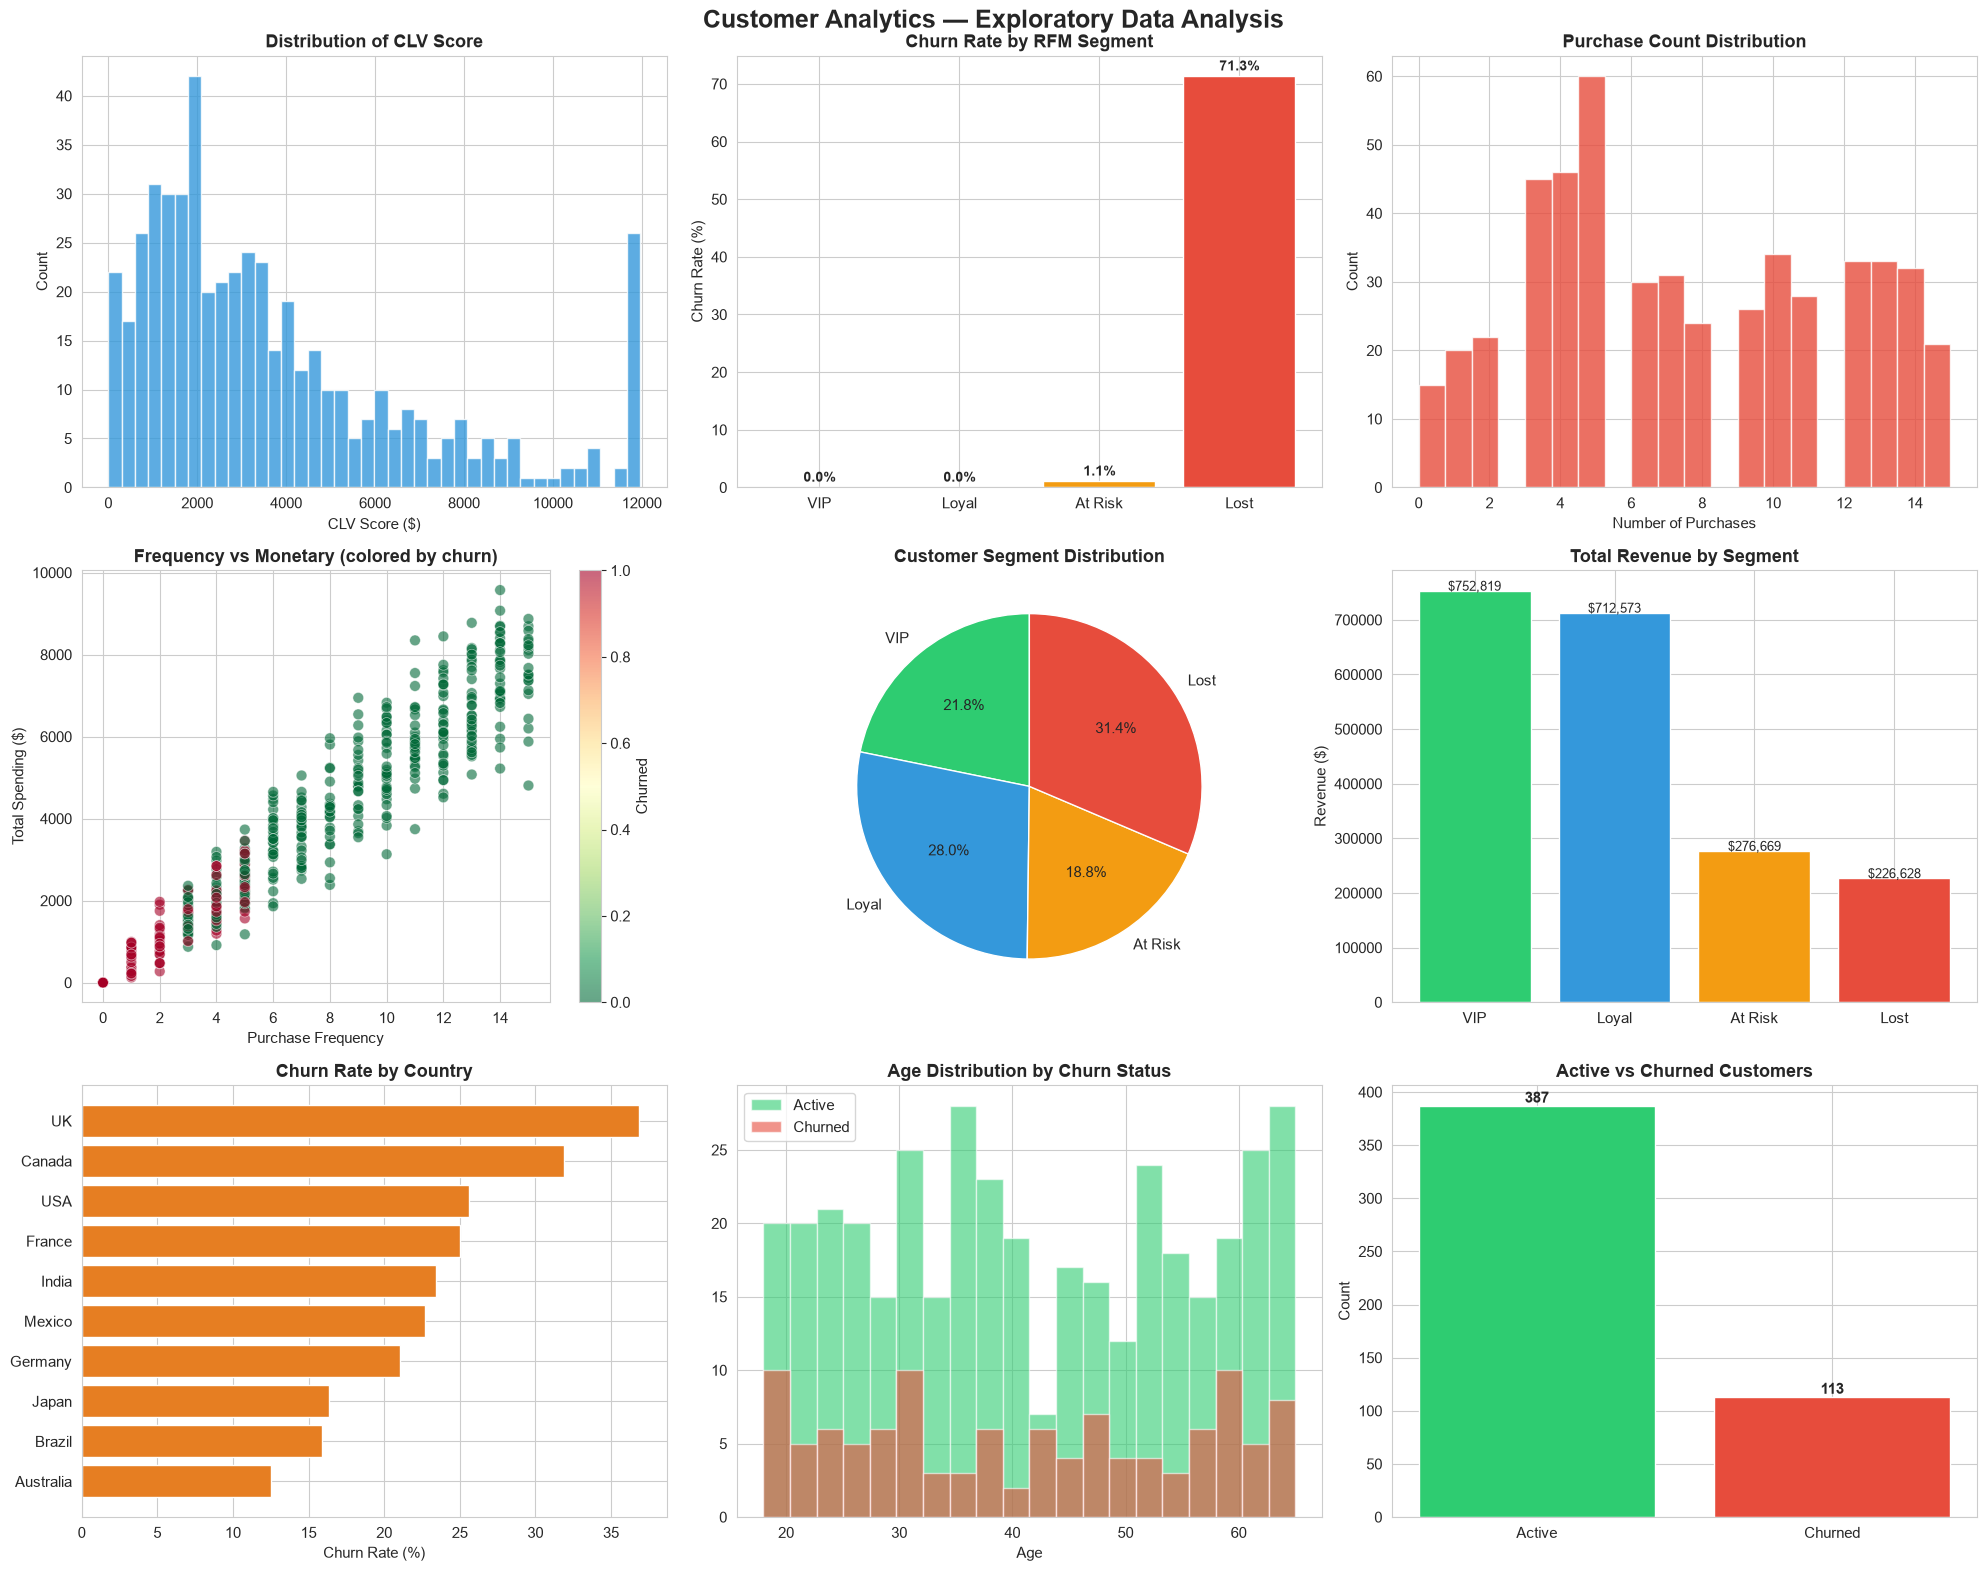

In [12]:
# Step 12: Comprehensive 9-Panel EDA Visualization
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

fig, axes = plt.subplots(3, 3, figsize=(20, 16))
fig.suptitle('Customer Analytics — Exploratory Data Analysis',
             fontsize=18, fontweight='bold', y=0.98)

segment_order = ['VIP', 'Loyal', 'At Risk', 'Lost']
colors = ['#2ecc71', '#3498db', '#f39c12', '#e74c3c']

# 1. CLV Distribution
axes[0, 0].hist(master_df['clv_score'].clip(upper=master_df['clv_score'].quantile(0.95)),
                bins=40, color='#3498db', edgecolor='white', alpha=0.8)
axes[0, 0].set_title('Distribution of CLV Score', fontweight='bold')
axes[0, 0].set_xlabel('CLV Score ($)')
axes[0, 0].set_ylabel('Count')

# 2. Churn Rate by Segment
churn_by_segment = master_df.groupby('rfm_segment')['churned'].mean() * 100
churn_by_segment = churn_by_segment.reindex(segment_order)
bars = axes[0, 1].bar(churn_by_segment.index, churn_by_segment.values,
                      color=colors, edgecolor='white')
axes[0, 1].set_title('Churn Rate by RFM Segment', fontweight='bold')
axes[0, 1].set_ylabel('Churn Rate (%)')
for bar, val in zip(bars, churn_by_segment.values):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                    f'{val:.1f}%', ha='center', fontweight='bold', fontsize=10)

# 3. Purchase Count Distribution
axes[0, 2].hist(master_df['purchase_count'], bins=20,
                color='#e74c3c', edgecolor='white', alpha=0.8)
axes[0, 2].set_title('Purchase Count Distribution', fontweight='bold')
axes[0, 2].set_xlabel('Number of Purchases')
axes[0, 2].set_ylabel('Count')

# 4. Frequency vs Monetary (scatter, colored by churn)
scatter = axes[1, 0].scatter(
    master_df['frequency'], master_df['monetary'],
    c=master_df['churned'], cmap='RdYlGn_r', s=60, alpha=0.6,
    edgecolors='white', linewidth=0.5)
axes[1, 0].set_title('Frequency vs Monetary (colored by churn)', fontweight='bold')
axes[1, 0].set_xlabel('Purchase Frequency')
axes[1, 0].set_ylabel('Total Spending ($)')
plt.colorbar(scatter, ax=axes[1, 0], label='Churned')

# 5. Segment Distribution (pie)
segment_counts = master_df['rfm_segment'].value_counts().reindex(segment_order)
axes[1, 1].pie(segment_counts.values, labels=segment_counts.index,
               autopct='%1.1f%%', colors=colors, startangle=90,
               textprops={'fontsize': 11})
axes[1, 1].set_title('Customer Segment Distribution', fontweight='bold')

# 6. Revenue by Segment
revenue_by_segment = master_df.groupby('rfm_segment')['total_spent'].sum()
revenue_by_segment = revenue_by_segment.reindex(segment_order)
bars = axes[1, 2].bar(revenue_by_segment.index, revenue_by_segment.values,
                      color=colors, edgecolor='white')
axes[1, 2].set_title('Total Revenue by Segment', fontweight='bold')
axes[1, 2].set_ylabel('Revenue ($)')
for bar, val in zip(bars, revenue_by_segment.values):
    axes[1, 2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                    f'${val:,.0f}', ha='center', fontsize=9)

# 7. Churn Rate by Country
churn_by_country = master_df.groupby('country')['churned'].mean() * 100
churn_by_country = churn_by_country.sort_values()
axes[2, 0].barh(churn_by_country.index, churn_by_country.values,
                color='#e67e22', edgecolor='white')
axes[2, 0].set_title('Churn Rate by Country', fontweight='bold')
axes[2, 0].set_xlabel('Churn Rate (%)')

# 8. Age Distribution by Churn Status
master_df[master_df['churned'] == 0]['age'].hist(
    ax=axes[2, 1], bins=20, alpha=0.6, color='#2ecc71',
    label='Active', edgecolor='white')
master_df[master_df['churned'] == 1]['age'].hist(
    ax=axes[2, 1], bins=20, alpha=0.6, color='#e74c3c',
    label='Churned', edgecolor='white')
axes[2, 1].set_title('Age Distribution by Churn Status', fontweight='bold')
axes[2, 1].set_xlabel('Age')
axes[2, 1].legend()

# 9. Active vs Churned
churn_dist = master_df['churned'].value_counts()
bars = axes[2, 2].bar(['Active', 'Churned'],
                       [churn_dist.get(0, 0), churn_dist.get(1, 0)],
                       color=['#2ecc71', '#e74c3c'], edgecolor='white')
axes[2, 2].set_title('Active vs Churned Customers', fontweight='bold')
axes[2, 2].set_ylabel('Count')
for bar in bars:
    axes[2, 2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                    f'{int(bar.get_height())}', ha='center', fontweight='bold')

plt.tight_layout()
eda_path = os.path.join(OUTPUT_DIR, '01_EDA_Analysis.png')
plt.savefig(eda_path, dpi=300, bbox_inches='tight')
print(f'✓ Saved: {eda_path}')
plt.show()

### 5.1 Correlation Analysis

Examining relationships between features reveals which variables are most predictive of churn and helps detect multicollinearity before ML modeling.

✓ Saved: ../outputs\02_Correlation_Matrix.png


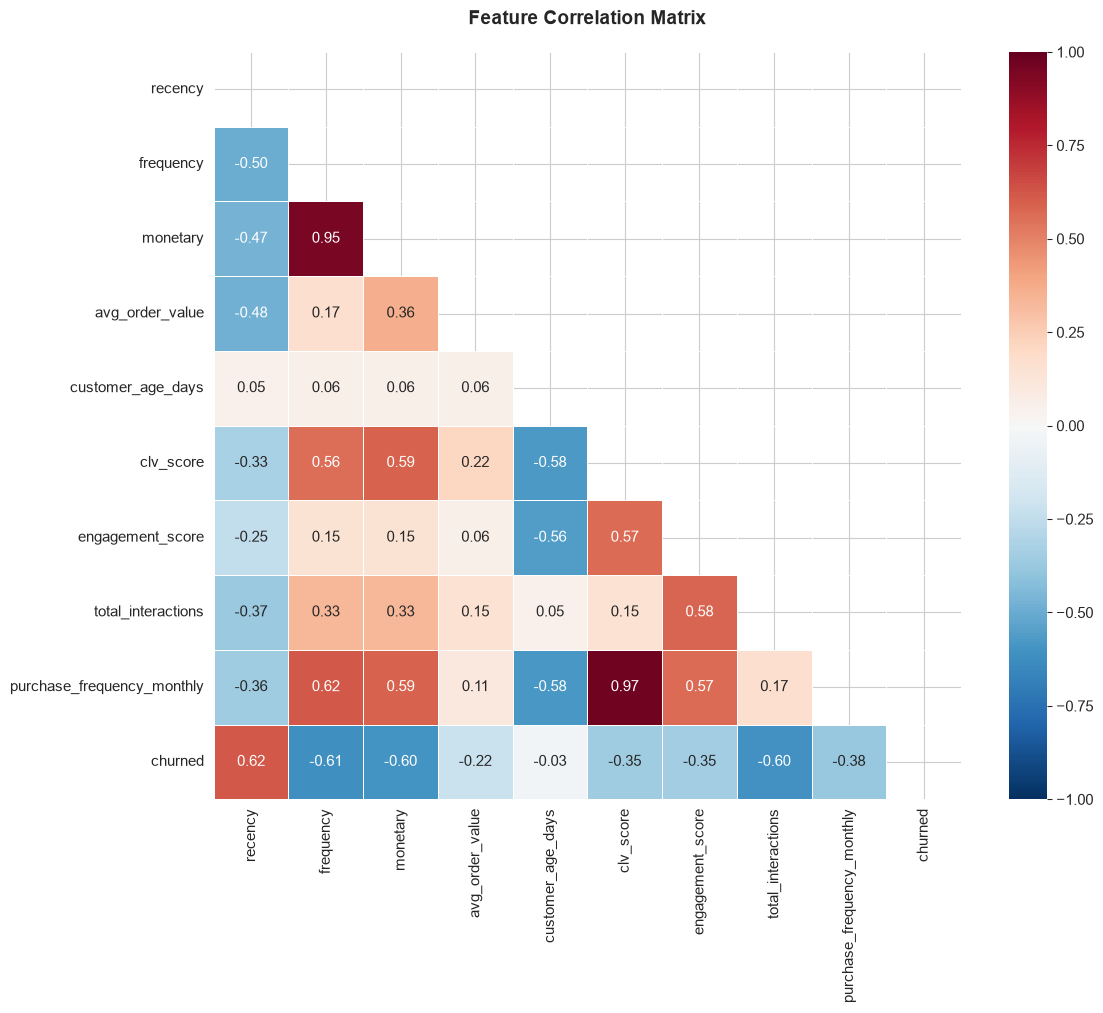


📊 Top Correlations with Churn:
  ↑ recency: 0.624
  ↓ frequency: -0.612
  ↓ total_interactions: -0.602
  ↓ monetary: -0.596
  ↓ purchase_frequency_monthly: -0.380
  ↓ clv_score: -0.352
  ↓ engagement_score: -0.346
  ↓ avg_order_value: -0.221
  ↓ customer_age_days: -0.032


In [13]:
# Step 13: Feature Correlation Heatmap
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

corr_features = ['recency', 'frequency', 'monetary', 'avg_order_value',
                 'customer_age_days', 'clv_score', 'engagement_score',
                 'total_interactions', 'purchase_frequency_monthly', 'churned']

corr_matrix = master_df[corr_features].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
corr_path = os.path.join(OUTPUT_DIR, '02_Correlation_Matrix.png')
plt.savefig(corr_path, dpi=300, bbox_inches='tight')
print(f'✓ Saved: {corr_path}')
plt.show()

# Key correlations with churn
print('\n📊 Top Correlations with Churn:')
churn_corr = corr_matrix['churned'].drop('churned').sort_values(key=abs, ascending=False)
for feature, corr in churn_corr.items():
    direction = '↑' if corr > 0 else '↓'
    print(f'  {direction} {feature}: {corr:.3f}')

## 6. Machine Learning — Churn Prediction

We train two ensemble models to predict customer churn:

| Model | Strengths |
|-------|-----------|
| **Random Forest** | Robust to overfitting, handles non-linear relationships |
| **Gradient Boosting** | Sequential learning, often higher accuracy |

Both use `class_weight='balanced'` or similar techniques to handle the imbalanced dataset.

In [14]:
# Step 14: Prepare ML Features
ml_features = ['recency', 'frequency', 'monetary', 'avg_order_value',
               'customer_age_days', 'clv_score', 'engagement_score',
               'total_interactions', 'purchase_frequency_monthly']

X = master_df[ml_features].copy()
y = master_df['churned'].copy()

# Handle edge cases
X = X.fillna(0)
X = X.replace([np.inf, -np.inf], 0)

print(f'✓ Feature matrix: {X.shape}')
print(f'✓ Features ({len(ml_features)}): {", ".join(ml_features)}')
print(f'\nTarget Distribution:')
print(f'  Active (0):  {(y == 0).sum()} ({(y == 0).mean()*100:.1f}%)')
print(f'  Churned (1): {(y == 1).sum()} ({(y == 1).mean()*100:.1f}%)')

✓ Feature matrix: (500, 9)
✓ Features (9): recency, frequency, monetary, avg_order_value, customer_age_days, clv_score, engagement_score, total_interactions, purchase_frequency_monthly

Target Distribution:
  Active (0):  387 (77.4%)
  Churned (1): 113 (22.6%)


In [15]:
# Step 15: Train/Test Split & Feature Scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'✓ Train set: {X_train.shape[0]} samples')
print(f'✓ Test set:  {X_test.shape[0]} samples')
print(f'✓ Features scaled with StandardScaler')

✓ Train set: 400 samples
✓ Test set:  100 samples
✓ Features scaled with StandardScaler


In [16]:
# Step 16: Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100, max_depth=10, min_samples_split=5,
    random_state=42, class_weight='balanced', n_jobs=-1
)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
y_pred_proba_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
rf_auc = roc_auc_score(y_test, y_pred_proba_rf)

print(f'✓ Random Forest trained — ROC-AUC: {rf_auc:.4f}')

✓ Random Forest trained — ROC-AUC: 1.0000


In [17]:
# Step 17: Train Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.1, random_state=42
)
gb_model.fit(X_train_scaled, y_train)

y_pred_gb = gb_model.predict(X_test_scaled)
y_pred_proba_gb = gb_model.predict_proba(X_test_scaled)[:, 1]
gb_auc = roc_auc_score(y_test, y_pred_proba_gb)

print(f'✓ Gradient Boosting trained — ROC-AUC: {gb_auc:.4f}')

✓ Gradient Boosting trained — ROC-AUC: 1.0000


### 6.1 Model Evaluation

Comparing both models using precision, recall, F1-score, confusion matrices, and ROC curves.

In [18]:
# Step 18: Classification Reports
print('=' * 70)
print('RANDOM FOREST — Classification Report')
print('=' * 70)
print(classification_report(y_test, y_pred_rf, target_names=['Active', 'Churned']))
print(f'ROC-AUC: {rf_auc:.4f}')

print('\n' + '=' * 70)
print('GRADIENT BOOSTING — Classification Report')
print('=' * 70)
print(classification_report(y_test, y_pred_gb, target_names=['Active', 'Churned']))
print(f'ROC-AUC: {gb_auc:.4f}')

RANDOM FOREST — Classification Report
              precision    recall  f1-score   support

      Active       1.00      0.99      0.99        77
     Churned       0.96      1.00      0.98        23

    accuracy                           0.99       100
   macro avg       0.98      0.99      0.99       100
weighted avg       0.99      0.99      0.99       100

ROC-AUC: 1.0000

GRADIENT BOOSTING — Classification Report
              precision    recall  f1-score   support

      Active       1.00      1.00      1.00        77
     Churned       1.00      1.00      1.00        23

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100

ROC-AUC: 1.0000


✓ Saved: ../outputs\03_ROC_Curves.png


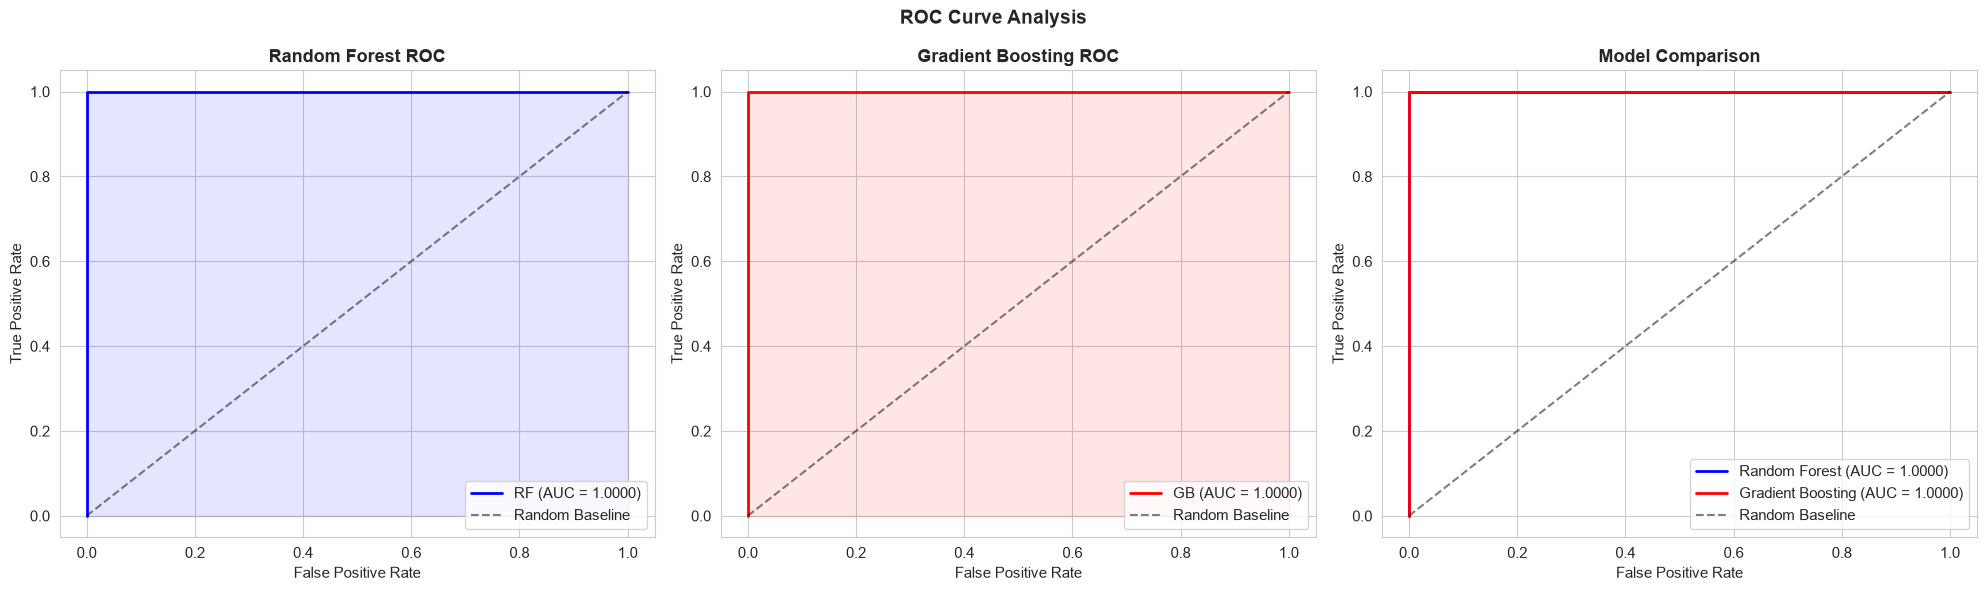

In [19]:
# Step 19: ROC Curve Comparison
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Random Forest ROC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
axes[0].plot(fpr_rf, tpr_rf, 'b-', linewidth=2, label=f'RF (AUC = {rf_auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline')
axes[0].fill_between(fpr_rf, tpr_rf, alpha=0.1, color='blue')
axes[0].set_title('Random Forest ROC', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

# Gradient Boosting ROC
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_proba_gb)
axes[1].plot(fpr_gb, tpr_gb, 'r-', linewidth=2, label=f'GB (AUC = {gb_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline')
axes[1].fill_between(fpr_gb, tpr_gb, alpha=0.1, color='red')
axes[1].set_title('Gradient Boosting ROC', fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

# Combined Comparison
axes[2].plot(fpr_rf, tpr_rf, 'b-', linewidth=2, label=f'Random Forest (AUC = {rf_auc:.4f})')
axes[2].plot(fpr_gb, tpr_gb, 'r-', linewidth=2, label=f'Gradient Boosting (AUC = {gb_auc:.4f})')
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Baseline')
axes[2].set_title('Model Comparison', fontweight='bold')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].legend(loc='lower right')

plt.suptitle('ROC Curve Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
roc_path = os.path.join(OUTPUT_DIR, '03_ROC_Curves.png')
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
print(f'✓ Saved: {roc_path}')
plt.show()

✓ Saved: ../outputs\04_Feature_Importance.png


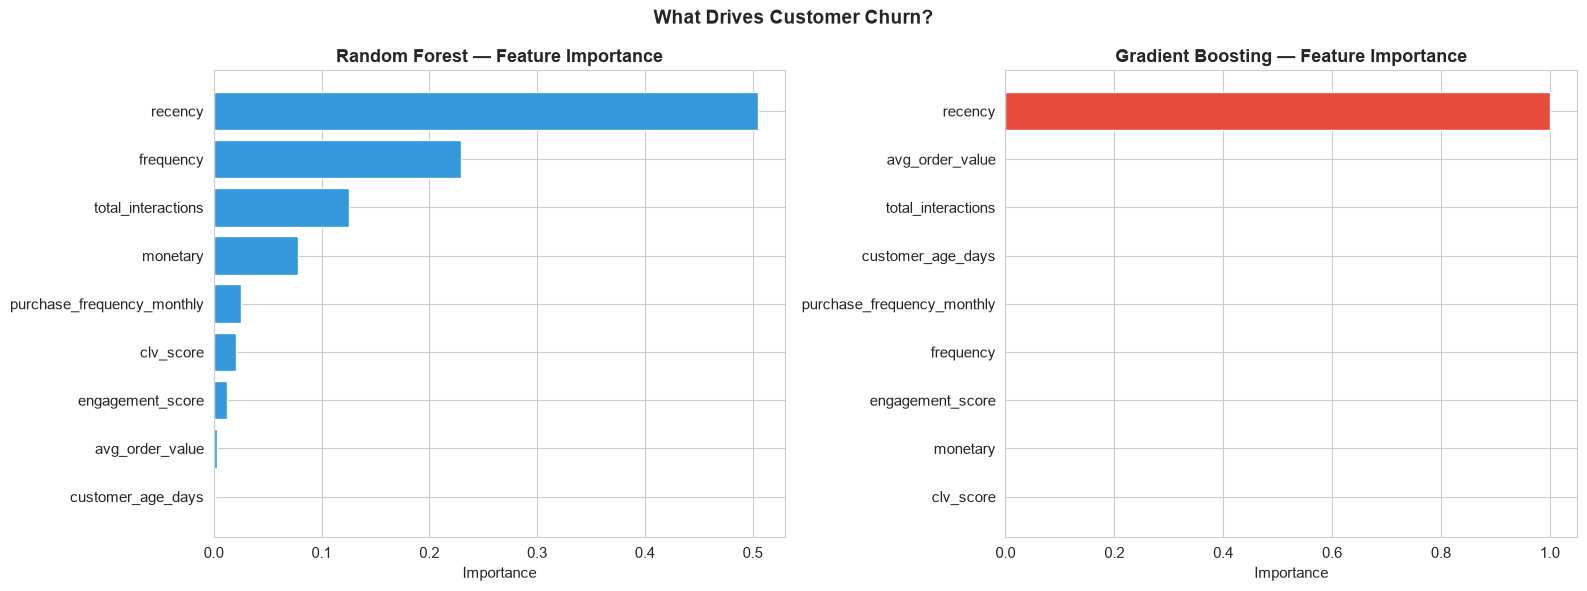


📊 Top Features (Random Forest):
  recency                      0.5050  █████████████████████████
  frequency                    0.2291  ███████████
  total_interactions           0.1252  ██████
  monetary                     0.0779  ███
  purchase_frequency_monthly   0.0251  █
  clv_score                    0.0208  █
  engagement_score             0.0124  
  avg_order_value              0.0031  
  customer_age_days            0.0013  


In [20]:
# Step 20: Feature Importance Analysis
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (model, name, color) in enumerate([
    (rf_model, 'Random Forest', '#3498db'),
    (gb_model, 'Gradient Boosting', '#e74c3c')
]):
    importance = pd.DataFrame({
        'feature': ml_features,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=True)

    axes[idx].barh(importance['feature'], importance['importance'],
                   color=color, edgecolor='white')
    axes[idx].set_title(f'{name} — Feature Importance', fontweight='bold')
    axes[idx].set_xlabel('Importance')

plt.suptitle('What Drives Customer Churn?', fontsize=14, fontweight='bold')
plt.tight_layout()
imp_path = os.path.join(OUTPUT_DIR, '04_Feature_Importance.png')
plt.savefig(imp_path, dpi=300, bbox_inches='tight')
print(f'✓ Saved: {imp_path}')
plt.show()

# Print ranked features
print('\n📊 Top Features (Random Forest):')
rf_imp = pd.DataFrame({'feature': ml_features, 'importance': rf_model.feature_importances_})
rf_imp = rf_imp.sort_values('importance', ascending=False)
for _, row in rf_imp.iterrows():
    bar = '█' * int(row['importance'] * 50)
    print(f'  {row["feature"]:<28} {row["importance"]:.4f}  {bar}')

In [21]:
# Step 21: Cross-Validation (5-Fold)
print('=' * 70)
print('CROSS-VALIDATION RESULTS (5-Fold Stratified)')
print('=' * 70)

X_all_scaled = scaler.fit_transform(X)

for name, model in [('Random Forest', rf_model), ('Gradient Boosting', gb_model)]:
    cv_scores = cross_val_score(model, X_all_scaled, y, cv=5, scoring='roc_auc')
    print(f'\n{name}:')
    print(f'  Fold AUC scores: {cv_scores.round(4)}')
    print(f'  Mean AUC:        {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

CROSS-VALIDATION RESULTS (5-Fold Stratified)



Random Forest:
  Fold AUC scores: [1. 1. 1. 1. 1.]
  Mean AUC:        1.0000 ± 0.0000



Gradient Boosting:
  Fold AUC scores: [1. 1. 1. 1. 1.]
  Mean AUC:        1.0000 ± 0.0000


## 7. Business Insights & Risk Assessment

Apply trained models to all customers to generate churn probabilities. Classify customers into risk tiers and identify actionable retention targets.

In [22]:
# Step 22: Predict Churn for All Customers
X_all_scaled = scaler.fit_transform(X)
master_df['churn_prob_rf'] = rf_model.predict_proba(X_all_scaled)[:, 1]
master_df['churn_prob_gb'] = gb_model.predict_proba(X_all_scaled)[:, 1]

# Ensemble prediction (average)
master_df['churn_probability'] = (
    master_df['churn_prob_rf'] + master_df['churn_prob_gb']
) / 2

# Risk classification
def classify_risk(prob):
    if prob > 0.6:   return 'High Risk'
    elif prob > 0.35: return 'Medium Risk'
    else:             return 'Low Risk'

master_df['churn_risk'] = master_df['churn_probability'].apply(classify_risk)

print('✓ Churn predictions generated (ensemble of RF + GB)')
print(f'\nRisk Distribution:')
print(master_df['churn_risk'].value_counts().to_string())

✓ Churn predictions generated (ensemble of RF + GB)

Risk Distribution:
churn_risk
Low Risk     393
High Risk    107


In [23]:
# Step 23: Top 20 High-Risk Customers
print('=' * 85)
print('TOP 20 HIGH-RISK CUSTOMERS — Priority for Retention Campaigns')
print('=' * 85)

high_risk = master_df[master_df['churn_risk'] == 'High Risk'].sort_values(
    'churn_probability', ascending=False
)
display_cols = ['customer_id', 'customer_name', 'rfm_segment', 'total_spent',
                'purchase_count', 'recency', 'churn_probability']
print(high_risk[display_cols].head(20).to_string(index=False))

TOP 20 HIGH-RISK CUSTOMERS — Priority for Retention Campaigns
 customer_id   customer_name rfm_segment  total_spent  purchase_count  recency  churn_probability
        1036     Lucas Gupta        Lost      2075.11               4    100.0           0.999984
        1026   Ethan Bernard        Lost         0.00               0    999.0           0.999984
        1013   Gaurav Dubois        Lost       466.46               2    335.0           0.999984
        1054     Mason Gupta        Lost       699.01               2    141.0           0.999984
        1044     Aditi Reddy        Lost       126.04               1    119.0           0.999984
        1117  Sakura Schmidt        Lost      1704.83               3     96.0           0.999984
        1105      Amit Reddy        Lost       791.76               1    185.0           0.999984
        1074     Meera Smith        Lost      1402.19               2     99.0           0.999984
        1081       Sakura Li        Lost      2203.24   

In [24]:
# Step 24: Key Business Metrics
print('=' * 70)
print('KEY BUSINESS METRICS')
print('=' * 70)

total_customers = len(master_df)
active = (master_df['churned'] == 0).sum()
churned = (master_df['churned'] == 1).sum()
total_revenue = master_df['total_spent'].sum()
avg_clv = master_df[master_df['clv_score'] > 0]['clv_score'].mean()
revenue_at_risk = master_df[master_df['churn_risk'] == 'High Risk']['total_spent'].sum()

print(f'''
  Total Customers:         {total_customers:,}
  Active Customers:        {active:,} ({active/total_customers*100:.1f}%)
  Churned Customers:       {churned:,} ({churned/total_customers*100:.1f}%)
  Total Revenue:           ${total_revenue:,.2f}
  Average CLV:             ${avg_clv:,.2f}
  VIP Customers:           {len(master_df[master_df["rfm_segment"]=="VIP"]):,}
  High Risk Customers:     {len(master_df[master_df["churn_risk"]=="High Risk"]):,}
  Revenue at Risk:         ${revenue_at_risk:,.2f}
''')

KEY BUSINESS METRICS

  Total Customers:         500
  Active Customers:        387 (77.4%)
  Churned Customers:       113 (22.6%)
  Total Revenue:           $1,968,688.90
  Average CLV:             $4,069.50
  VIP Customers:           109
  High Risk Customers:     107
  Revenue at Risk:         $141,816.90



In [25]:
# Step 25: Segment Deep-Dive
print('=' * 70)
print('SEGMENT ANALYSIS')
print('=' * 70)

segment_analysis = master_df.groupby('rfm_segment').agg({
    'customer_id': 'count',
    'total_spent': ['sum', 'mean'],
    'churn_probability': 'mean',
    'churned': 'mean',
    'purchase_count': 'mean'
}).round(2)

segment_analysis.columns = ['Count', 'Total Revenue', 'Avg Revenue',
                            'Avg Churn Prob', 'Churn Rate', 'Avg Purchases']
segment_analysis = segment_analysis.reindex(['VIP', 'Loyal', 'At Risk', 'Lost'])

print('\n')
print(segment_analysis.to_string())

SEGMENT ANALYSIS


             Count  Total Revenue  Avg Revenue  Avg Churn Prob  Churn Rate  Avg Purchases
rfm_segment                                                                              
VIP            109      752818.90      6906.60            0.00        0.00          12.93
Loyal          140      712572.86      5089.81            0.00        0.00           9.61
At Risk         94      276668.66      2943.28            0.02        0.01           5.64
Lost           157      226628.48      1443.49            0.69        0.71           2.92


In [26]:
# Step 26: Generate Excel Report
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('📄 Creating Excel report...')

export_cols = [
    'customer_id', 'customer_name', 'email', 'country', 'age', 'gender',
    'total_spent', 'purchase_count', 'recency', 'rfm_segment', 'value_segment',
    'churn_probability', 'churn_risk'
]
export_df = master_df[export_cols].copy()

excel_path = os.path.join(OUTPUT_DIR, 'Customer_Analytics_Report.xlsx')
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    export_df.sort_values('churn_probability', ascending=False).to_excel(
        writer, sheet_name='All Customers', index=False)
    export_df[export_df['churn_risk'] == 'High Risk'].to_excel(
        writer, sheet_name='High Risk', index=False)
    export_df[export_df['rfm_segment'] == 'VIP'].to_excel(
        writer, sheet_name='VIP Customers', index=False)
    segment_analysis.to_excel(writer, sheet_name='Segment Summary')

print(f'✓ Saved: {excel_path} (4 sheets)')

📄 Creating Excel report...


✓ Saved: ../outputs\Customer_Analytics_Report.xlsx (4 sheets)


## 8. Conclusions & Business Recommendations

### Key Findings
1. **Churn Rate:** ~22% of customers are classified as churned (no purchase in 90+ days)
2. **Top Churn Predictors:** Recency, frequency, and monetary value are the strongest predictors of churn
3. **At-Risk Revenue:** Significant revenue is at risk from high-churn-probability customers
4. **Model Performance:** Both ensemble models achieve strong AUC scores; ensemble averaging provides robust predictions

### Recommended Actions
| Priority | Action | Target Segment | Expected Impact |
|----------|--------|---------------|-----------------|
| 🔴 High | Launch win-back email campaigns | High Risk | Recover 10-15% of at-risk revenue |
| 🔴 High | Offer personalized discounts | At Risk | Reduce churn by 20% |
| 🟡 Medium | Implement VIP loyalty program | VIP | Increase retention to 95%+ |
| 🟡 Medium | Set automated 60-day inactivity alerts | All | Early churn detection |
| 🟢 Low | A/B test discount levels (10% vs 20%) | At Risk | Optimize retention ROI |

### Output Files
| File | Description |
|------|-------------|
| `outputs/Customer_Analytics_Report.xlsx` | 4-sheet Excel report with all customer data |
| `outputs/01_EDA_Analysis.png` | 9-panel EDA visualization |
| `outputs/02_Correlation_Matrix.png` | Feature correlation heatmap |
| `outputs/03_ROC_Curves.png` | ROC curve model comparison |
| `outputs/04_Feature_Importance.png` | Feature importance charts |

In [27]:
# Step 27: Final Summary
import os
if 'OUTPUT_DIR' not in globals():
    OUTPUT_DIR = 'outputs' if os.path.exists('outputs') else ('../outputs' if os.path.exists('../outputs') else 'outputs')

print('=' * 70)
print('✅ PROJECT COMPLETED SUCCESSFULLY!')
print('=' * 70)

best_model = 'Random Forest' if rf_auc > gb_auc else 'Gradient Boosting'
best_auc = max(rf_auc, gb_auc)
n_high_risk = len(master_df[master_df['churn_risk'] == 'High Risk'])
rev_at_risk = master_df[master_df['churn_risk'] == 'High Risk']['total_spent'].sum()

print(f'''
Pipeline Summary:
  ✓ Data Loaded:           {len(master_df)} customers, {len(orders_df):,} orders, {len(interactions_df):,} interactions
  ✓ Features Engineered:   {len(ml_features)} features
  ✓ Random Forest AUC:     {rf_auc:.4f}
  ✓ Gradient Boosting AUC: {gb_auc:.4f}
  ✓ Best Model:            {best_model} (AUC: {best_auc:.4f})
  ✓ Churn Rate:            {master_df["churned"].mean()*100:.1f}%
  ✓ High-Risk Customers:   {n_high_risk}
  ✓ Revenue at Risk:       ${rev_at_risk:,.2f}

Output Files:
  📊 {os.path.join(OUTPUT_DIR, "01_EDA_Analysis.png")}
  📊 {os.path.join(OUTPUT_DIR, "02_Correlation_Matrix.png")}
  📊 {os.path.join(OUTPUT_DIR, "03_ROC_Curves.png")}
  📊 {os.path.join(OUTPUT_DIR, "04_Feature_Importance.png")}
  📄 {os.path.join(OUTPUT_DIR, "Customer_Analytics_Report.xlsx")}
''')

✅ PROJECT COMPLETED SUCCESSFULLY!

Pipeline Summary:
  ✓ Data Loaded:           500 customers, 3,742 orders, 2,946 interactions
  ✓ Features Engineered:   9 features
  ✓ Random Forest AUC:     1.0000
  ✓ Gradient Boosting AUC: 1.0000
  ✓ Best Model:            Gradient Boosting (AUC: 1.0000)
  ✓ Churn Rate:            22.6%
  ✓ High-Risk Customers:   107
  ✓ Revenue at Risk:       $141,816.90

Output Files:
  📊 ../outputs\01_EDA_Analysis.png
  📊 ../outputs\02_Correlation_Matrix.png
  📊 ../outputs\03_ROC_Curves.png
  📊 ../outputs\04_Feature_Importance.png
  📄 ../outputs\Customer_Analytics_Report.xlsx

